In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_DIR = "../data/troupe/TLS"

In [4]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

print(type(data))

<class 'list'>


In [105]:
t = data[4]
t.describe()
# t.convert_to_ultrametric()
t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	169
Total number of nodes:	337
Rooted:	Yes
Most distant node:	CTTACCGAGTGCCCGT-1
Max. distance:	0.993721
Number of leaf nodes:	169
Total number of nodes:	337
Rooted:	Yes
Most distant node:	CTTACCGAGTGCCCGT-1
Max. distance:	0.993721


In [106]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    root_id = id(t)

    for node in t.traverse():
        node_id = id(node)

        # collect attributes safely
        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        # optional attributes (only if present)
        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(id(node.up), node_id, weight=node.dist)
    
    G.graph["root"] = root_id

    return G

In [107]:
T = ete_to_nx(t)
T

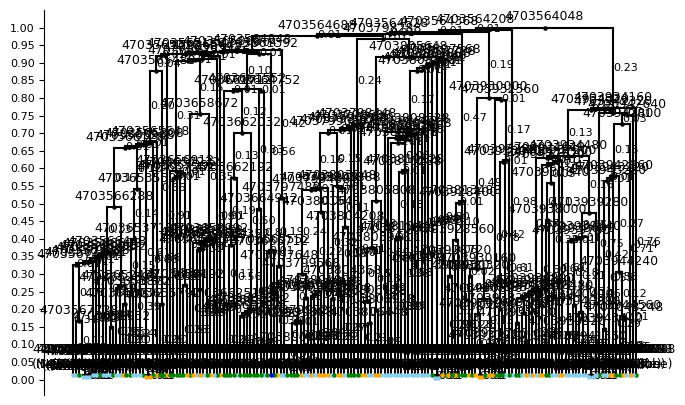

In [108]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'])

In [109]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [110]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [111]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9874415284795893 0.9937212757749091


In [112]:
scale = 1 / min_dist  # scale to make the min leaf at 1

In [113]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [114]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

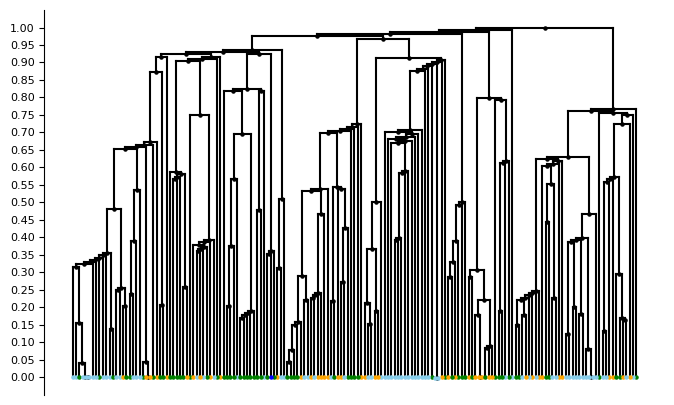

In [115]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [116]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [117]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999999999999999 1.00000066205228


## Differentiation Map from CARTA

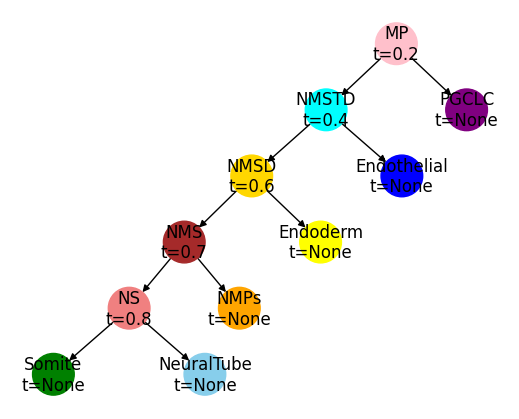

In [118]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

diff_times = {
    "MP": 0.2,
    "NMSTD": 0.4,
    "NMSD": 0.6,
    "NMS": 0.7,
    "NS": 0.8,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [119]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [120]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, diff_T)

Children have > 1 types ['Somite', 'NeuralTube']
Children have > 1 types ['Somite', 'NMPs']
Children have > 1 types ['Somite', 'NMPs']
Children have > 1 types ['Somite', 'NMPs']
Children have > 1 types ['Somite', 'NeuralTube']
Children have > 1 types ['Somite', 'NeuralTube']
Children have > 1 types ['Somite', 'NMPs']
Children have > 1 types ['NMPs', 'NeuralTube']
Children have > 1 types ['Somite', 'NMPs']
Children have > 1 types ['NMPs', 'NeuralTube']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NS', 'NMPs']
Children have > 1 types ['NMS', 'Endo

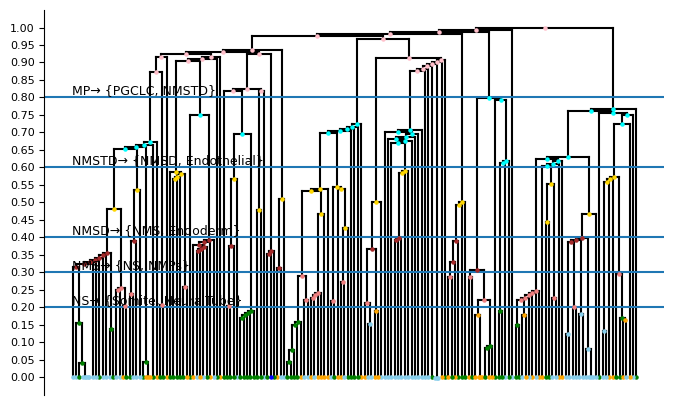

In [121]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [104]:
def find_lowest_common_ancestor(cell_lineage_T, state_1, state_2):
    T = cell_lineage_T.copy()
    lineage_nodes = list(T.nodes(data=True))
    combined_sorted = sorted(
        lineage_nodes,
        key=lambda x: x[1].get('T')
    )

    for node in combined_sorted:
        node_id, node_data = node
        if 'state' in node_data: continue

        children = list(T.successors(node_id))
        children_types = [T.nodes[ch]['state'] 
                        for ch in children 
                        if 'state' in T.nodes[ch]]
        
        unique_types = list(set(children_types))

        if len(unique_types) > 1:
            if state_1 in unique_types and state_2 in unique_types:
                return node_data['T'], node_id
        
        T.nodes[node_id]["state"] = unique_types[0]

In [52]:
find_lowest_common_ancestor(T, "NeuralTube", "Somite")

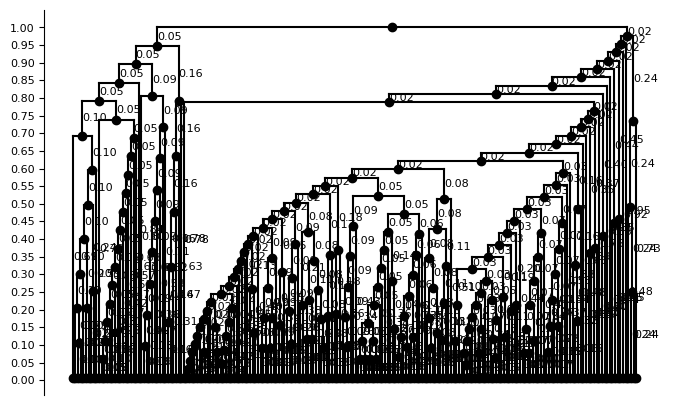

In [28]:
t.convert_to_ultrametric()
T = ete_to_nx(t)
draw_ultrametric_tree(T, root=T.graph['root'])